In [1]:
%reset -f
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from collections import deque
from datetime import datetime

import sys
sys.path.append("../../tools")
import functions as func
import syndesign as sds
import prepare as prep
import generation as gr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(eva)
#importlib.reload(prep)
# importlib.reload(func)
# importlib.reload(sds)


In [ ]:
# load_dir1 = Path(f"../../saved_models/sta_entropy_15fold/sp3to20_MD_transpt3_r9")
# load_dir2 = Path(f"../../saved_models/diversity_15fold/sp3to20_MD_transpt3_r1")
# load_dir3 = Path(f"../../saved_models/num_stable_states_15fold/sp3to20_NS_transpt3_r7")

load_dir1 = Path(f"../../saved_models/sta_entropy_ver2.0_upto20/sp3to20_MD_transpt3_r1")
load_dir2 = Path(f"../../saved_models/diversity_ver2.0_upto20/sp3to20_MD_transpt3_r1")
load_dir3 = Path(f"../../saved_models/num_stable_states_ver2.0_upto20/sp3to20_NS_transpt3_r1")

emodel = func.load_saved_model_MD(load_dir1, device)
dmodel = func.load_saved_model_MD(load_dir2, device)
nmodel = func.load_saved_model_NS(load_dir3, device)
epredictor = func.Predictor(emodel)
dpredictor = func.Predictor(dmodel)
npredictor = func.Predictor(nmodel)
MaxNum = emodel["NumSpecies"]

predictor = func.Predictor(emodel)


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [ ]:
def modify_according_parameters_NS5(
    n_real, MaxNum, Xnum0, npredictor, device,
    target_states=1,
    target_prob=0.5,
    lr=1e-3, max_steps=6000, patience=100, tol=1e-4
):
    """
    Maximize the predicted probability of obtaining exactly
    target_states stable states until it reaches target_prob.

    Success criterion:
        P(N=target_states) >= target_prob

    Gamma interaction sign structure is preserved.
    """

    # ============================================================
    # Initial state
    # ============================================================

    X_initial = torch.tensor(
        Xnum0,
        dtype=torch.float32,
        device=device
    )

    with torch.no_grad():

        target_prob_initial = npredictor.predict_tensor_NS_prob(X_initial, state_number=target_states).item()
        N0 = npredictor.predict_array_NS(Xnum0, device).item()

    print(
        f"\ninitial, "
        f"P(N={target_states})={target_prob_initial:.6f}, "
        f"predicted stable states={N0}, "
        f"target probability={target_prob:.3f}"
    )

    # ============================================================
    # Initial parameters
    # ============================================================

    Xnum = Xnum0.copy()
    paraidx = np.array([], dtype=int)

    best_X_history = []
    best_prob_history = []
    best_N_history = []

    # Check whether the initial state already reaches the target
    if target_prob_initial >= target_prob:

        print("Initial state already reaches the target probability.")

        df_results = pd.DataFrame({
            "X": [Xnum0.copy()],
            "target_probability": [target_prob_initial],
            "stable_state_number": [N0]
        })

        return df_results, paraidx

    # ============================================================
    # Gradually increase number of optimized parameters
    # ============================================================

    for paranum in range(int(n_real + n_real**2)):

        df_sens = sds.sensitivity_analysis(
            Xnum,
            npredictor,
            n_real,
            "abs",
            "P",
            device,
            state_number=target_states
        )

        mask, paraidx = sds.build_mask_single2(
            paranum + 1,
            paraidx,
            df_sens,
            MaxNum,
            device
        )

        X0 = torch.tensor(
            Xnum,
            dtype=torch.float32,
            device=device
        )

        Xs0 = sds.X_to_scaled(X0, MaxNum)
        Xs = torch.nn.Parameter(Xs0.clone())

        optimizer = torch.optim.Adam(
            [Xs],
            lr=lr
        )

        recent_prob = deque(maxlen=patience)

        best_prob = -np.inf
        best_Xs = None
        best_N = None

        reached_target = False

        # ========================================================
        # Optimization
        # ========================================================

        for step in range(int(max_steps)):

            optimizer.zero_grad()

            X = sds.scaled_to_X(Xs, MaxNum)

            target_prob_pred = npredictor.predict_tensor_NS_prob(
                X,
                state_number=target_states
            )

            loss = -target_prob_pred.mean()
            loss.backward()

            # Only update selected parameters
            Xs.grad *= mask

            optimizer.step()

            # ====================================================
            # Parameter projection
            # ====================================================

            with torch.no_grad():

                X_real = sds.scaled_to_X(Xs, MaxNum)

                sds.project_parameters(
                    X_real,
                    MaxNum
                )

                X_real = sds.project_gamma_sign(
                    X_real,
                    X_initial,
                    MaxNum
                )

                Xs.copy_(
                    sds.X_to_scaled(X_real, MaxNum)
                )

                Xs[mask == 0] = Xs0[mask == 0]

            # ====================================================
            # Evaluate current solution
            # ====================================================

            with torch.no_grad():

                X_eval = sds.scaled_to_X(Xs, MaxNum)

                prob_val = npredictor.predict_tensor_NS_prob(
                    X_eval,
                    state_number=target_states
                ).item()

                X_eval_np = X_eval.detach().cpu().numpy()

                predicted_N = npredictor.predict_array_NS(
                    X_eval_np,
                    device
                ).item()

            # ====================================================
            # Save best solution according to target probability
            # ====================================================

            if prob_val > best_prob:

                best_prob = prob_val
                best_Xs = Xs.detach().clone()
                best_N = predicted_N

            # ====================================================
            # Success criterion
            # ====================================================

            if prob_val >= target_prob:

                print(
                    f"Target reached at step {step}: "
                    f"P(N={target_states})={prob_val:.6f}, "
                    f"stable states={predicted_N}"
                )

                best_prob = prob_val
                best_Xs = Xs.detach().clone()
                best_N = predicted_N

                reached_target = True
                break

            # ====================================================
            # Convergence detection
            # ====================================================

            recent_prob.append(prob_val)

            if len(recent_prob) == patience:

                prob_range = max(recent_prob) - min(recent_prob)

                if prob_range <= tol:
                    break

        # ========================================================
        # Check optimization result
        # ========================================================

        if best_Xs is None:
            raise RuntimeError("No valid solution found")

        # ========================================================
        # Update Xnum
        # ========================================================

        Xs = best_Xs
        X = sds.scaled_to_X(Xs, MaxNum)

        # Restore unselected parameters
        X[mask == 0] = X0[mask == 0]

        Xnum = X.detach().cpu().numpy().copy()

        # ========================================================
        # Print result
        # ========================================================

        print(
            f"paranum={paranum + 1}, "
            f"P(N={target_states})={best_prob:.6f}, "
            f"predicted stable states={best_N}"
        )

        # ========================================================
        # Save history
        # ========================================================

        best_X_history.append(Xnum.copy())
        best_prob_history.append(best_prob)
        best_N_history.append(best_N)

        # ========================================================
        # Final success condition
        # ========================================================

        if reached_target:

            print(
                f"Optimization finished with "
                f"{paranum + 1} parameters."
            )

            break

    # ============================================================
    # Results
    # ============================================================

    df_results = pd.DataFrame({
        "X": [Xnum0.copy()] + best_X_history,
        "target_probability": [target_prob_initial] + best_prob_history,
        "stable_state_number": [N0] + best_N_history
    })

    return df_results, paraidx

n_real = 10
target_states = 1  # Select the target number of stable states
target_prob = 0.7

#df = pd.read_csv("../Fig4/gamma5.csv")
df = pd.read_csv("../Fig4/random2_upto20.csv")
df = df[df["fluctuation"] == 0]

Xnum_pad = df.iloc[:, :MaxNum**2+MaxNum].values
df["states_number"] = npredictor.predict_array_NS(Xnum_pad, device)

sub_df = df[(df["richness"] == n_real) & (df["states_number"] == 4)]

samnum = 5
results = []

for samid in range(samnum):
#for samid in range(10, 15):

    print(f"\n--dealing with sample {samid}--")

    Xnum0 = sub_df.iloc[samid, :MaxNum**2+MaxNum].values

    df_results, paraidx = modify_according_parameters_NS5(
        n_real,
        MaxNum,
        Xnum0,
        npredictor,
        device,
        target_states=target_states,
        target_prob=target_prob
    )

    final_N = df_results["stable_state_number"].iloc[-1]

    results.append({
        "sample_id": samid,
        "richness": n_real,
        "target_states": target_states,

        "initial_X": Xnum0.copy(),
        "final_X": df_results["X"].iloc[-1],

        "initial_target_probability": df_results["target_probability"].iloc[0],
        "final_target_probability": df_results["target_probability"].iloc[-1],

        "initial_N": df_results["stable_state_number"].iloc[0],
        "final_N": final_N,

        "reach_target": (final_N == target_states),

        "paranum": len(paraidx),
        "paraidx": paraidx.copy(),

        "X_list": df_results["X"].values,
        "target_probability_list": df_results["target_probability"].values,
        "N_list": df_results["stable_state_number"].values
    })



--dealing with sample 0--

initial, P(N=1)=0.000298, predicted stable states=4, target probability=0.700
paranum=1, P(N=1)=0.001410, predicted stable states=4
paranum=2, P(N=1)=0.011983, predicted stable states=3
paranum=3, P(N=1)=0.011983, predicted stable states=3
paranum=4, P(N=1)=0.017398, predicted stable states=3
paranum=5, P(N=1)=0.033627, predicted stable states=3
paranum=6, P(N=1)=0.043697, predicted stable states=3
paranum=7, P(N=1)=0.130790, predicted stable states=2
paranum=8, P(N=1)=0.351073, predicted stable states=2
paranum=9, P(N=1)=0.476853, predicted stable states=1
paranum=10, P(N=1)=0.500331, predicted stable states=1
paranum=11, P(N=1)=0.508171, predicted stable states=1


KeyboardInterrupt: 

In [34]:
df_result = pd.DataFrame(results)
df_result.to_pickle(f"efficient_raise_N{target_states}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pkl")


In [25]:
df = pd.read_pickle("efficient_raise_N_20261106_184011.pkl")


In [ ]:
df = pd.DataFrame(results)

n_real = 10
featgam = n_real**2 - n_real
MaxNum = 20
task_num = 0

compare = []
for idx in range(df.shape[0]):
#for idx in range(1):

    df_sample = df.iloc[idx, :]
    ini_Xnum_pad = df_sample["initial_X"]
    fin_Xnum_pad = df_sample["final_X"]

    pre_ini_N = npredictor.predict_array_NS(ini_Xnum_pad, device).item()
    pre_fin_N = npredictor.predict_array_NS(fin_Xnum_pad, device).item()

    ini_Xnum = prep.recovery_Xnum(ini_Xnum_pad, n_real, MaxNum)
    fin_Xnum = prep.recovery_Xnum(fin_Xnum_pad, n_real, MaxNum)
    ini_Xynum = gr.predict_numerical(ini_Xnum, n_real, repeat=200, timespan=np.arange(0,800.1,.1))
    fin_Xynum = gr.predict_numerical(fin_Xnum, n_real, repeat=200, timespan=np.arange(0,800.1,.1))

    compare.append({
        "sample_idx": idx,
        "initial_X": df_sample["initial_X"],
        "pre_ini_y": pre_ini_N,
        "real_ini_y": ini_Xynum[0, n_real + featgam + n_real + task_num],
        "final_X": df_sample["final_X"],
        "pre_fin_y": pre_fin_N,
        "real_fin_y": fin_Xynum[0, n_real + featgam + n_real + task_num],
    })

df_compare = pd.DataFrame(compare)
df_compare.to_pickle(f"efficient_raise_N_vali_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pkl")


Dealing with richness 10
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199


Dealing with richness 10
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
8

In [37]:
Xnum_list = results[0]["X_list"].tolist()


In [20]:
df_result = pd.DataFrame(results)
df_result.to_pickle(f"efficient_raise_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pkl")


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline
from itertools import islice

df_result = pd.read_pickle("efficient_raise_N_vali_20261106_185055.pkl")
#sub_df = df_result.iloc[:40, :]


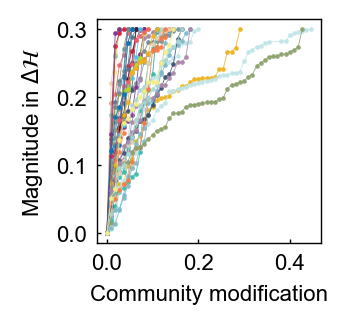

In [ ]:
from datetime import datetime

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis label (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick label (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})

plt.figure(figsize=(1.4,1.4), dpi=200)

colors = ['#F15F6C', '#32BDA8', '#EEB21C', '#BFE5E8', '#E8D0AE', "#7EBACC",
          '#567589', '#7297A0', '#3E516F', '#76888C',"#F87947",
          '#D61F3E', '#8CA06B', '#7F308E', '#0873BA',"#A886A8",
          '#A6D7D3', '#F6ED86', '#88C29C', '#451B2B', '#4CBFEE', "#B7E020"]

#for sample_id in range(df_result.shape[0]):
for sample_id in range(40):

    if (df_result["reach_target"][sample_id])==False:
        continue

    y_list = np.concatenate([[df_result["initial_y"][sample_id]], df_result["y_list"][sample_id]])
    y_list = np.maximum(y_list, 0)
    para_list = np.arange(df_result["paranum"][sample_id]+1)

    upper_paranum = df_result["richness"][sample_id] + (df_result["richness"][sample_id])**2

    x = y_list - df_result["initial_y"][sample_id] 
    y = para_list/upper_paranum 

    keep_idx = [0]
    for i in range(1, len(x)):
        if x[i] >= x[keep_idx[-1]]:
            keep_idx.append(i)
    plotx = y[keep_idx]
    ploty = x[keep_idx]

    color = colors[sample_id % len(colors)]
    plt.plot(
        plotx,
        ploty,
        marker="o",
        markersize=0.7,
        linewidth=0.3,
        alpha=0.9,
        color=color,
        rasterized=True,
    )

plt.xlabel("Community modification") 
plt.ylabel(r"Magnitude in $\Delta\mathcal{H}$") 
#plt.ylabel(r"Target $\mathcal{H}$") # target H

plt.tick_params(direction='in')

plt.subplots_adjust(
    left=0.18,
    right=0.98,
    bottom=0.18,
    top=0.98,
)

plt.savefig(
    f"efficient_raise_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches="tight",
    transparent=True
)
plt.show()
